<a href="https://colab.research.google.com/github/adrianbarriga/TALLER-2-IA/blob/main/PRACTICA_02_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#PRACTICA 02 IA

##Celda de verificación

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt
print(" Todas las librerías cargadas correctamente")

 Todas las librerías cargadas correctamente


##Dataset de estudiantes

In [ ]:
import numpy as np
import pandas as pd
datos = {
 "nombre": ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
 "edad": [21, 23, 20, 25, 22, 21],
 "promedio_gpa": [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
 "horas_estudio": [18, 10, 22, 6, 15, 12],
 "distancia_km": [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
 "carrera": [
 "Computación","Computación","Redes","Redes","Computación","Redes"],
 "nivel_ingles": [
 "Básico", "Intermedio","Avanzado","Básico","Avanzado","Intermedio"],
 "beca": [1, 0, 1, 0, 1, 0],
 "aprobado": ["Sí", "No", "Sí", "No", "Sí", "No"]
}
df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")
print(df)
print(f"\nDimensiones del dataset: {df.shape}")


   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Sí  
1   Intermedio     0       No  
2     Avanzado     1       Sí  
3       Básico     0       No  
4     Avanzado     1       Sí  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)
   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computa

##Actividad 1.1: Identifica la estructura.

####• P1. ¿Cuántas instancias (filas) tiene este dataset? ¿Qué representa cada instancia en el mundo real?

##### • En el dataset hay 6 instancias (filas), como lo confirma df.shape = (6, 9).
##### • Cada fila representa a un estudiante real con sus datos personales y académicos: edad, promedio, horas de estudio, distancia a la universidad, carrera, nivel de inglés, si tiene beca y si aprobó.

####• P2. Lista todos los atributos (columnas). Ahora sepáralos en dos grupos: ¿cuáles actuarían como features y cuál sería el label si tu objetivo fuera predecir si un estudiante aprueba o no?

##### • Atributos (9): nombre, edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca, aprobado.
##### • Features: edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles y beca.
##### • Label: aprobado, porque es la variable que queremos predecir (Sí / No).
##### • La columna nombre se excluye de los features (ver P3).

####• P3. La columna nombre es un atributo, pero ¿debería ser un feature para un modelo de ML? ¿Por qué sí o por qué no?

##### • No. El nombre solo identifica a la persona; no tiene relación causal con aprobar o no.
##### • Cada valor es prácticamente único, así que el modelo no puede generalizar a partir de él: solo memorizaría que "Ana aprueba", lo que provoca sobreajuste (overfitting).
##### • Además, usarlo podría introducir sesgos (por ejemplo de género u origen). Se usa como identificador, no como feature.

##Actividad 1.2: Clasifica las variables.

In [ ]:
clasificacion = {
    "columna":        ["edad", "promedio_gpa", "horas_estudio", "distancia_km",
                       "carrera", "nivel_ingles", "beca", "aprobado"],
    "cuantitativa_o_cualitativa": ["Cuantitativa", "Cuantitativa", "Cuantitativa", "Cuantitativa",
                                   "Cualitativa", "Cualitativa", "Cualitativa", "Cualitativa"],
    "discreta_o_continua":        ["Discreta", "Continua", "Discreta", "Continua",
                                   "Discreta", "Discreta", "Discreta", "Discreta"],
    "nominal_u_ordinal":          ["NA", "NA", "NA", "NA",
                                   "Nominal", "Ordinal", "Nominal", "Nominal"]
}
df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)

         columna cuantitativa_o_cualitativa discreta_o_continua  \
0           edad               Cuantitativa            Discreta   
1   promedio_gpa               Cuantitativa            Continua   
2  horas_estudio               Cuantitativa            Discreta   
3   distancia_km               Cuantitativa            Continua   
4        carrera                Cualitativa            Discreta   
5   nivel_ingles                Cualitativa            Discreta   
6           beca                Cualitativa            Discreta   
7       aprobado                Cualitativa            Discreta   

  nominal_u_ordinal  
0                NA  
1                NA  
2                NA  
3                NA  
4           Nominal  
5           Ordinal  
6           Nominal  
7           Nominal  


####• P4. nivel_ingles tiene los valores Básico, Intermedio y Avanzado. ¿Es nominal u ordinal? ¿En qué te basas para decidirlo? ¿Importa esa distinción a la hora de entrenar un modelo?

##### • Es ordinal, porque sus categorías tienen un orden natural: Básico < Intermedio < Avanzado.
##### • Sí importa. Al ser ordinal se puede codificar respetando el orden (Básico=0, Intermedio=1, Avanzado=2) con un OrdinalEncoder.
##### • Si fuera nominal (como carrera) habría que usar One-Hot Encoding, porque asignar números induciría al modelo a creer en un orden que no existe.

####• P5. La columna beca solo contiene 0 y 1. ¿Es cuantitativa discreta o cualitativa nominal? Justifica tu respuesta.

##### • Es cualitativa nominal (binaria). Los números 0 y 1 son solo etiquetas de "No tiene beca" / "Sí tiene beca".
##### • Calcular su media (0.5) no describe a ningún estudiante: no existe "media beca". Esa media solo sirve como proporción (el 50% tiene beca), lo cual confirma que es una categoría y no una cantidad.

##Actividad 1.3: Inspeccionando tipos de datos.

In [ ]:
print("Tipos de datos detectados por pandas:")
print(df.dtypes)
print("\nEstadísticas descriptivas (solo numéricas):")
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas (solo numéricas):
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


####• P6. ¿Coinciden los tipos que detecta pandas (int64, object, float64) con tu clasificación teórica de la actividad 1.2? Señala al menos un caso donde no coincidan y explica por qué pandas puede estar "equivocado" desde la perspectiva conceptual.

##### • No coinciden en todos los casos. beca aparece como int64 (numérica), pero conceptualmente es cualitativa nominal; por eso describe() le calcula media y desviación, que no tienen sentido.
##### • nivel_ingles aparece como object igual que carrera, pero una es ordinal y la otra nominal: pandas no detecta el orden.
##### • Pandas solo mira cómo está almacenado el dato (tipo de dato en memoria), no lo que significa. La clasificación conceptual la debe hacer el analista.

####• P7. Observa las estadísticas descriptivas. ¿Qué columna tiene mayor dispersión (std)? ¿Qué problema podría ocasionar esa diferencia de escala si alimentas este dataset directamente a un algoritmo como KNN?

##### • distancia_km tiene la mayor dispersión (std ≈ 14.69), frente a promedio_gpa (std ≈ 1.19) o edad (std ≈ 1.79).
##### • KNN calcula distancias (por ejemplo euclidiana) entre estudiantes. Sin escalar, las diferencias en kilómetros dominarían el cálculo y el promedio o la edad casi no influirían.
##### • El modelo terminaría agrupando estudiantes por lo lejos que viven y no por su rendimiento, lo que daría predicciones sesgadas.

##FASE 2. Escalado con NumPy

##Actividad 2.1: Preparando los datos

In [ ]:
# Extraemos SOLO las columnas numéricas continuas para esta fase
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)

print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape}  →  {X.shape[0]} instancias, {X.shape[1]} features")

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3)  →  6 instancias, 3 features


####• P8. ¿Por qué excluimos edad y beca de esta matriz aunque también son numéricas? ¿Tiene sentido escalar la columna beca que solo contiene 0 y 1?

##### • beca es una variable categórica codificada como 0/1, no una medida numérica real, así que no se trata como dato continuo.
##### • edad es discreta y tiene muy poca variación (20 a 25 años); en esta fase solo se busca practicar con variables continuas de escalas muy distintas.
##### • No tiene sentido escalar beca: ya está en el rango [0, 1]. Min-Max la dejaría igual y Z-Score la convertiría en valores como ±1 sin aportar nada.

##Actividad 2.2: Normalización Min-Max

In [ ]:
def min_max_manual(X):
    """
    Normalización Min-Max: transforma cada columna al rango [0, 1]
    Fórmula: x' = (x - min) / (max - min)
    """
    X_min = X.min(axis=0)   # mínimo por columna
    X_max = X.max(axis=0)   # máximo por columna
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)

print("=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")

print("\nDatos normalizados (Min-Max):")
df_minmax = pd.DataFrame(X_minmax, columns=[c+"_mm" for c in columnas_numericas])
print(df_minmax.round(4))

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005


####• P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0? ¿Y uno de 1.0?

##### • Cualquier columna queda en el rango [0, 1]: mínimo 0.0 y máximo 1.0 (verificado en la celda de abajo).
##### • 0.0 representa al estudiante con el valor más bajo de esa columna (por ejemplo Carlos en promedio_gpa, María en distancia_km).
##### • 1.0 representa al estudiante con el valor más alto (María en promedio_gpa y horas_estudio, Carlos en distancia_km).

In [ ]:
print("Mínimo por columna:", X_minmax.min(axis=0))
print("Máximo por columna:", X_minmax.max(axis=0))

Mínimo por columna: [0. 0. 0.]
Máximo por columna: [1. 1. 1.]


####• P10. Fíjate en la columna distancia_km. Carlos vive a 40.2 km, que es un valor extremo. Si llega un nuevo estudiante que vive a 80 km y vuelves a normalizar, ¿qué le pasará al valor transformado de todos los demás estudiantes? ¿Es eso un problema? ¿Por qué?

##### • Todos los valores se comprimen hacia 0, porque el nuevo máximo (80 km) pasa a ser el 1.0. Carlos baja de 1.0 a ≈ 0.50 y Luis de 0.36 a ≈ 0.18 (ver celda de abajo).
##### • Sí es un problema: un solo dato extremo cambia la representación de todos los demás, reduce la resolución entre ellos y obliga a recalcular la transformación cada vez que aparece un nuevo máximo.

In [ ]:
X_80 = np.vstack([X, [8.5, 14, 80.0]])   # nuevo estudiante a 80 km
X_80_mm, _, _ = min_max_manual(X_80)

print(f"{'Estudiante':<10} {'Antes':>8} {'Con 80 km':>10}")
for j, nom in enumerate(list(df["nombre"]) + ["Nuevo"]):
    antes = f"{X_minmax[j, 2]:.4f}" if j < len(X_minmax) else "-"
    print(f"{nom:<10} {antes:>8} {X_80_mm[j, 2]:>10.4f}")

Estudiante    Antes  Con 80 km
Ana          0.0431     0.0215
Luis         0.3604     0.1793
María        0.0000     0.0000
Carlos       1.0000     0.4975
Sofía        0.1091     0.0543
Diego        0.2005     0.0997
Nuevo             -     1.0000


##Actividad 2.3: Estandarización Z-Score

In [ ]:
def zscore_manual(X):
    """
    Z-Score: transforma cada columna a media=0 y desv.est.=1
    Fórmula: z = (x - media) / desviacion_estandar
    """
    media = X.mean(axis=0)
    std   = X.std(axis=0)       # desviación estándar de la población
    X_z   = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)

print("=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv.Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")

print("\nDatos estandarizados (Z-Score):")
df_z = pd.DataFrame(X_zscore, columns=[c+"_z" for c in columnas_numericas])
print(df_z.round(4))

=== RESULTADO Z-SCORE ===
Feature                 Media    Desv.Est.
------------------------------------------
promedio_gpa            7.983        1.088
horas_estudio          13.833        5.241
distancia_km           12.050       13.407

Datos estandarizados (Z-Score):
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499


####• P11. Después de aplicar Z-Score, ¿cuál es la media y la desviación estándar de cada columna? Verifica que tus resultados lo confirmen. (En la guía esta pregunta aparece repetida como P9.)

##### • Cada columna queda con media ≈ 0 y desviación estándar = 1 (verificado en la celda de abajo).
##### • A diferencia de Min-Max, Z-Score no tiene un mínimo ni un máximo fijos: los valores pueden ser negativos o mayores que 1.
##### • Un valor de 0 representa a un estudiante exactamente en la media del grupo, y un valor de 1 a alguien una desviación estándar por encima.

In [ ]:
print("Media por columna:", X_zscore.mean(axis=0).round(10))
print("Std por columna:  ", X_zscore.std(axis=0))

Media por columna: [ 0. -0.  0.]
Std por columna:   [1. 1. 1.]


####• P12. Carlos tiene horas_estudio = 6. Después del Z-Score, su valor transformado es negativo. ¿Qué significa eso en términos estadísticos? ¿Significa que Carlos estudia "mal"? ¿Qué dice ese valor sobre su posición relativa al grupo?

##### • Su valor es ≈ -1.49: Carlos estudia 1.49 desviaciones estándar por debajo de la media del grupo (13.8 horas).
##### • No significa que estudie "mal": el signo negativo solo indica que está por debajo del promedio. Z-Score es una medida relativa, no un juicio de calidad.
##### • Indica que es de los que menos horas estudian dentro de este grupo en particular; en otro grupo su z podría ser distinto.

####• P13. Compara los valores de Carlos y Sofía para distancia_km después de Min-Max y después de Z-Score. ¿Cuál de las dos transformaciones te parece más informativa sobre la "rareza" de vivir a 40 km? Argumenta.

##### • Min-Max: Carlos = 1.000, Sofía = 0.109. Z-Score: Carlos = 2.100, Sofía = -0.518.
##### • Z-Score es más informativo. Decir que Carlos está a 2.1 desviaciones estándar de la media indica claramente que es un caso atípico (más de 2σ).
##### • Min-Max solo dice que Carlos es el valor máximo, pero no cuán lejos está del resto: siempre habría un 1.0, sea o no un caso raro.

##Actividad 2.4: Comparación visual de las tres columnas

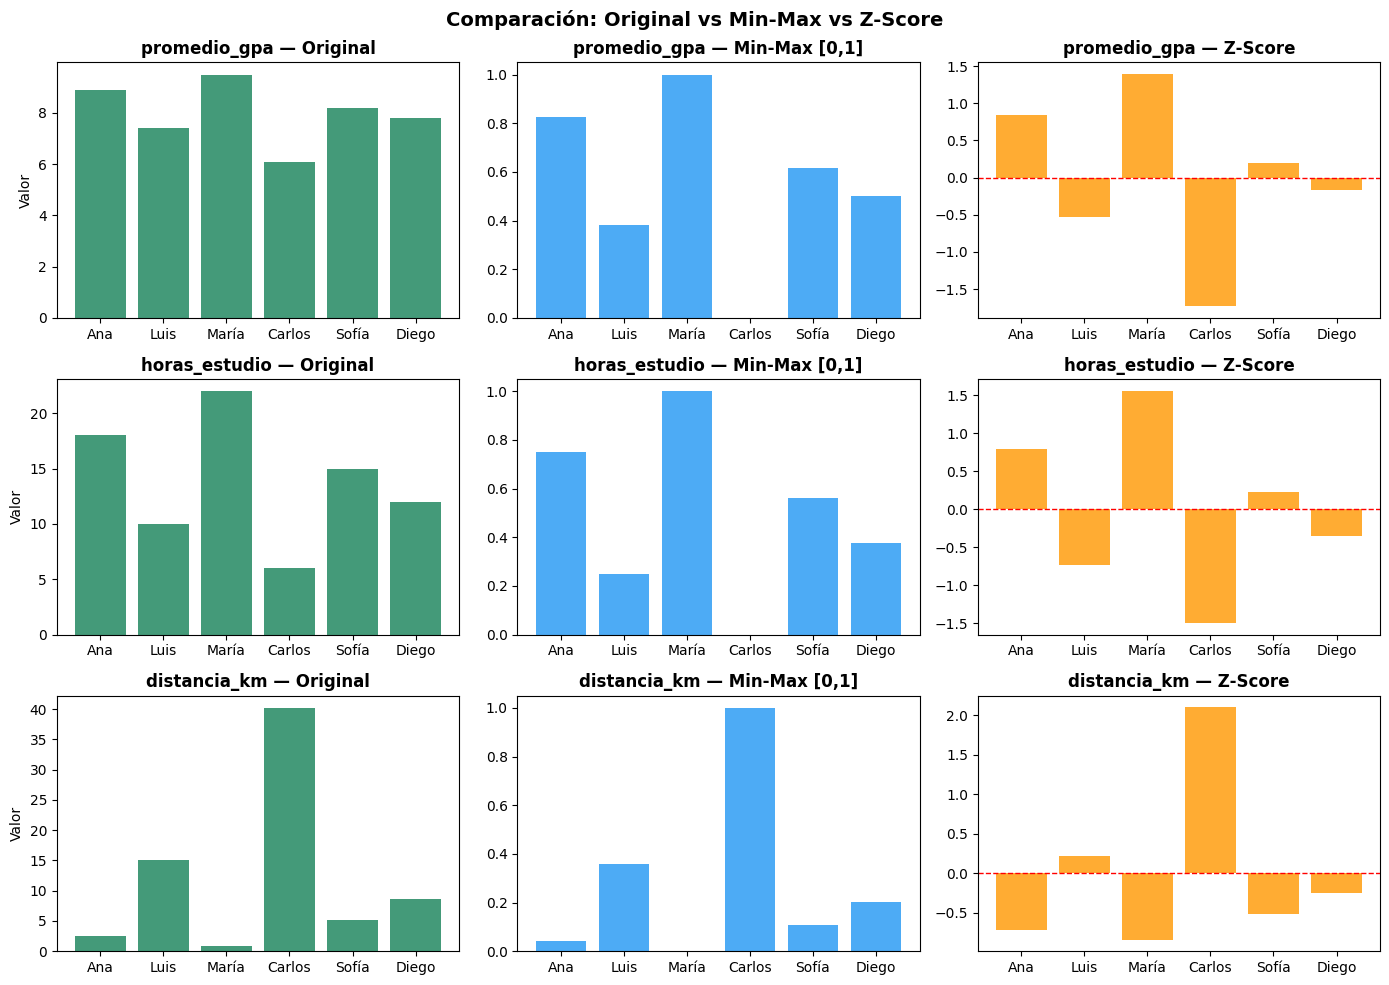

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values
for i, col in enumerate(columnas_numericas):
    # Original
    axes[i, 0].bar(nombres, X[:, i], color="#158158", alpha=0.8)
    axes[i, 0].set_title(f"{col} — Original", fontweight="bold")
    axes[i, 0].set_ylabel("Valor")
    # Min-Max
    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
    axes[i, 1].set_title(f"{col} — Min-Max [0,1]", fontweight="bold")
    # Z-Score
    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
    axes[i, 2].axhline(0, color="red", linestyle="--", linewidth=1)
    axes[i, 2].set_title(f"{col} — Z-Score", fontweight="bold")
plt.suptitle(
    "Comparación: Original vs Min-Max vs Z-Score", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.savefig("comparacion_escalado.png", dpi=100)
plt.show()


####• P14. Observa la gráfica de distancia_km. Las proporciones relativas entre estudiantes, ¿se mantienen igual en las tres versiones? ¿Qué es lo que realmente cambia entre Original, Min-Max y Z-Score?

##### • Sí. El orden de los estudiantes y las distancias relativas entre ellos se mantienen: Carlos sigue siendo el más lejano y María la más cercana, y las barras conservan su forma.
##### • Lo único que cambia es la escala y el punto de referencia (el eje Y). Min-Max desplaza y comprime los datos a [0, 1]; Z-Score los centra en 0 (por eso aparecen negativos) y los mide en desviaciones estándar.
##### • Ambas son transformaciones lineales, así que no deforman la información.

##Actividad 2.5: Simulando un outlier extremo

In [ ]:
# Añadimos un estudiante con una distancia extrema
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])  # 120 km

# Aplicamos Min-Max sobre los datos CON outlier
X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)

# Aplicamos Z-Score sobre los datos CON outlier
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)
nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):
    print(f"{nombres_ext[j]:<10} {X_con_outlier[j,2]:>10.1f} "
          f"{X_mm_con_outlier[j,2]:>10.4f} {X_z_con_outlier[j,2]:>10.4f}")

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


####• P15. Observa lo que ocurre con los valores de los otros estudiantes en Min-Max después de agregar el outlier de 120 km. ¿Qué problema genera esto? ¿Por qué Z-Score es más robusto ante este caso? ¿Existe alguna técnica mejor aún?

##### • Con Min-Max, los 6 estudiantes originales quedan aplastados entre 0.00 y 0.33 (Carlos baja de 1.0 a 0.33). Casi todo el rango [0, 1] lo ocupa un solo dato y se pierde la capacidad de diferenciar al resto.
##### • Z-Score depende de la media y la desviación de todos los datos, no solo de los extremos. El outlier queda claramente marcado (z ≈ 2.33) y los demás conservan valores diferenciables (de -0.67 a 0.32). Aun así no es inmune: la media y la std también se desplazan.
##### • Sí: el RobustScaler, que usa la mediana y el rango intercuartílico (IQR), casi no se ve afectado por valores extremos. También se puede aplicar una transformación logarítmica o recortar (clipping) los outliers.

##FASE 3. Dataset real con Pandas: Palmer Penguins

In [ ]:
import pandas as pd

# Cargamos el dataset directamente desde Hugging Face
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)

print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head(8))
print(f"\nDimensiones: {df_penguins.shape}")
print(f"\nColumnas: {list(df_penguins.columns)}")

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
6       3625.0  female  2007  
7       4675.0    male  2007  

Dimensiones: (344, 

##Actividad 3.1: Exploración inicial obligatoria

In [ ]:
print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())

print("\n=== VALORES ÚNICOS EN COLUMNAS CATEGÓRICAS ===")
for col in df_penguins.select_dtypes(include='object').columns:
    print(f"{col}: {df_penguins[col].unique()}")


=== TIPOS DE DATOS ===
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

=== VALORES NULOS ===
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

=== ESTADÍSTICAS DESCRIPTIVAS ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
count      342.000000     342.000000         342.000000   342.000000   
mean        43.921930      17.151170         200.915205  4201.754386   
std          5.459584       1.974793          14.061714   801.954536   
min         32.100000      13.100000         172.000000  2700.000000   
25%         39.225000      15.600000         190.000000  3550.000000   
50%         44.450000      17.30000

####• P16. Identifica para este dataset: ¿cuántas instancias tiene? ¿Cuáles son las features numéricas? ¿Cuál sería el label más lógico para una tarea de clasificación?

##### • Tiene 344 instancias (pingüinos) y 8 columnas.
##### • Features numéricas: bill_length_mm, bill_depth_mm, flipper_length_mm y body_mass_g. year también es numérica, pero solo indica el año de registro y no describe al pingüino.
##### • El label más lógico es species (Adelie, Gentoo, Chinstrap): predecir la especie a partir de sus medidas.

####• P17. ¿Hay valores nulos? ¿En qué columnas? ¿Por qué es importante tratar los valores nulos antes de aplicar escalado? ¿Qué pasaría si escalas con NaN presentes?

##### • Sí: 2 nulos en cada columna numérica (bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g) y 11 en sex.
##### • Los escaladores calculan min, max, media o std; con NumPy, un solo NaN hace que esos cálculos den NaN y toda la columna escalada quede en NaN.
##### • sklearn ignora los NaN al ajustar, pero los deja en el resultado, y la mayoría de modelos (KNN, regresión, SVM) lanzan error al recibirlos. Por eso primero se eliminan o se imputan.

##Actividad 3.2: Clasificación de variables del dataset

In [ ]:
clasificacion_penguins = {
    "columna": ["species", "island", "bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g", "sex", "year"],
    "cuantitativa_o_cualitativa": ["Cualitativa", "Cualitativa", "Cuantitativa", "Cuantitativa",
                                   "Cuantitativa", "Cuantitativa", "Cualitativa", "Cuantitativa"],
    "discreta_o_continua": ["Discreta", "Discreta", "Continua", "Continua",
                            "Continua", "Continua", "Discreta", "Discreta"],
    "nominal_u_ordinal": ["Nominal", "Nominal", "NA", "NA", "NA", "NA", "Nominal", "NA"]
}
print(pd.DataFrame(clasificacion_penguins))

             columna cuantitativa_o_cualitativa discreta_o_continua  \
0            species                Cualitativa            Discreta   
1             island                Cualitativa            Discreta   
2     bill_length_mm               Cuantitativa            Continua   
3      bill_depth_mm               Cuantitativa            Continua   
4  flipper_length_mm               Cuantitativa            Continua   
5        body_mass_g               Cuantitativa            Continua   
6                sex                Cualitativa            Discreta   
7               year               Cuantitativa            Discreta   

  nominal_u_ordinal  
0           Nominal  
1           Nominal  
2                NA  
3                NA  
4                NA  
5                NA  
6           Nominal  
7                NA  


####• P18. Para cada columna de df_penguins, clasifica su tipo completo. Presta especial atención a sex e island. ¿Son las dos nominales? ¿Cambiaría la respuesta si ordenamos las islas por temperatura promedio del océano?

##### • La clasificación completa está en la tabla de arriba.
##### • Sí, ambas son nominales: sex (male/female) e island (Torgersen, Biscoe, Dream) son categorías sin un orden natural entre ellas.
##### • Si ordenamos las islas por temperatura, el orden no viene de la isla sino de otra variable (la temperatura). En ese caso se podría tratar como ordinal, o mejor aún sustituirla por la temperatura como variable cuantitativa continua. Por sí sola, island sigue siendo nominal.

##Actividad 3.3: Preprocesamiento y escalado

In [ ]:
# Paso 1: Eliminar filas con valores nulos
df_clean = df_penguins.dropna()
print(f"Filas originales: {len(df_penguins)}  →  Filas limpias: {len(df_clean)}")

# Paso 2: Seleccionar features numéricas
features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]
X_penguins = df_clean[features_num].values

print("\nEstadísticas ANTES del escalado:")
print(pd.DataFrame(X_penguins, columns=features_num).describe().round(2))

Filas originales: 344  →  Filas limpias: 333

Estadísticas ANTES del escalado:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


####• P19. Mira las escalas de body_mass_g (en gramos, ~3500–6000) vs bill_depth_mm (en mm, ~13–21). Si entrenas un modelo con estos datos sin escalar, ¿cuál variable tendrá más peso en el cálculo de distancia? ¿Es eso justo biológicamente?

##### • body_mass_g tendrá muchísimo más peso: su rango es de 3600 g, frente a solo 8.4 mm de bill_depth_mm. Una diferencia de 100 g pesaría más que toda la variación del pico.
##### • No es justo biológicamente. La profundidad del pico es tan importante (o más) para distinguir especies; su menor peso se debe solo a la unidad de medida, no a su relevancia. Por eso hay que escalar.

##Actividad 3.4: Análisis de distribuciones

In [ ]:
# Paso 3: Aplicar Min-Max
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

# Paso 4: Aplicar Z-Score
zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

# Paso 5: Comparar estadísticas
print("\n--- Min-Max ---")
print(pd.DataFrame(X_mm, columns=features_num).describe().round(4))

print("\n--- Z-Score ---")
print(pd.DataFrame(X_zs, columns=features_num).describe().round(4))


--- Min-Max ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean           0.4325         0.4839             0.4910       0.4186
std            0.1989         0.2344             0.2376       0.2237
min            0.0000         0.0000             0.0000       0.0000
25%            0.2691         0.2976             0.3051       0.2361
50%            0.4509         0.5000             0.4237       0.3750
75%            0.6000         0.6667             0.6949       0.5764
max            1.0000         1.0000             1.0000       1.0000

--- Z-Score ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean          -0.0000        -0.0000             0.0000      -0.0000
std            1.0015         1.0015             1.0015       1.0015
min           -2.1780        -2.0673            -2.0699      -1.8744


HISTOGRAMAS ORIGINAL VS MIN-MAX VS Z-SCORE (PARA RESPONDER P20 Y P21)

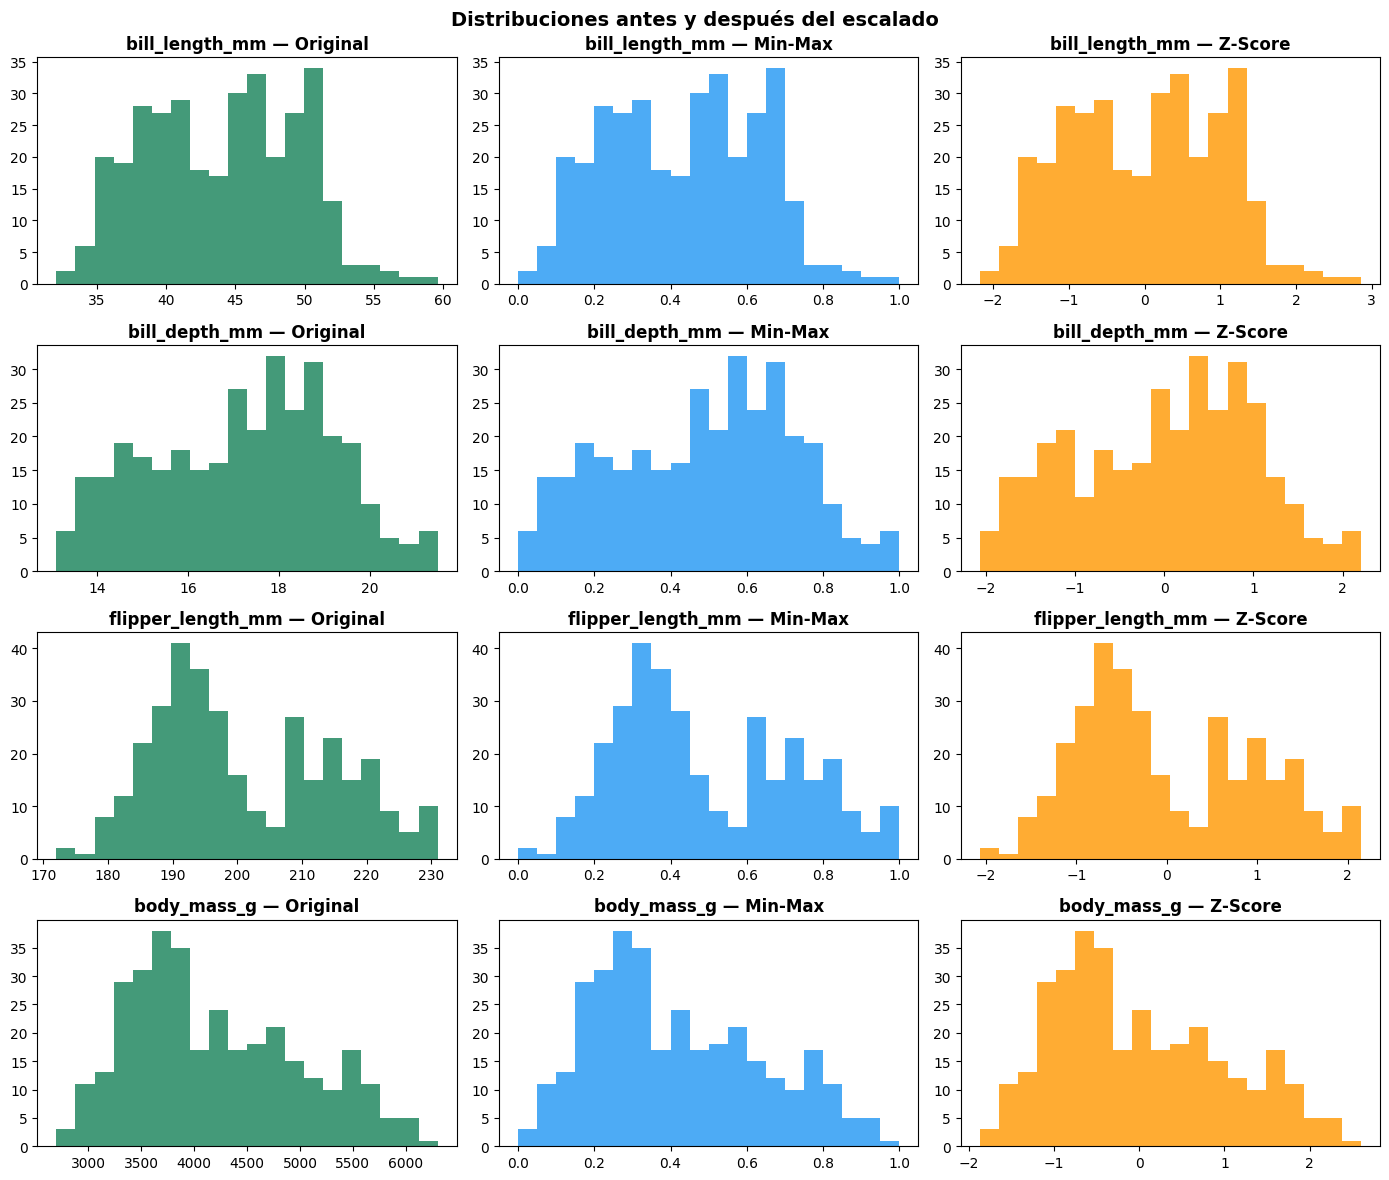

Asimetría (skew) de cada feature:
bill_length_mm       0.045
bill_depth_mm       -0.150
flipper_length_mm    0.360
body_mass_g          0.472
dtype: float64


In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
versiones = [("Original", X_penguins, "#158158"), ("Min-Max", X_mm, "#2196F3"), ("Z-Score", X_zs, "#FF9800")]

for i, col in enumerate(features_num):
    for j, (titulo, datos_v, color) in enumerate(versiones):
        axes[i, j].hist(datos_v[:, i], bins=20, color=color, alpha=0.8)
        axes[i, j].set_title(f"{col} — {titulo}", fontweight='bold')

plt.suptitle("Distribuciones antes y después del escalado", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Asimetría (skew) de cada feature:")
print(df_clean[features_num].skew().round(3))

####• P20. ¿El escalado cambia la forma de la distribución (histograma) o solo la escala de los ejes? ¿Por qué importa esa respuesta cuando evaluamos normalidad de los datos?

##### • Solo cambia la escala del eje horizontal. Los histogramas tienen exactamente la misma forma, porque Min-Max y Z-Score son transformaciones lineales: desplazan y estiran, pero no deforman.
##### • Importa porque escalar no vuelve normal a una variable. Si una feature es asimétrica o bimodal, lo seguirá siendo después del Z-Score. La normalidad se evalúa igual antes o después, y si se necesita una distribución más gaussiana hay que usar transformaciones no lineales (log, Box-Cox, Yeo-Johnson).

####• P21. Observa la distribución de body_mass_g. ¿Se parece a una campana de Gauss (distribución normal) o tiene alguna asimetría? ¿Afecta eso a la elección entre Min-Max y Z-Score?

##### • No es una campana perfecta: tiene una asimetría positiva (skew ≈ 0.47), con una cola hacia los pesos altos, y se ve algo bimodal porque los Gentoo son mucho más pesados que Adelie y Chinstrap.
##### • Sí afecta. Z-Score funciona mejor cuando los datos son aproximadamente normales, porque la media y la std describen bien a la distribución; con asimetría, la media se desplaza hacia la cola.
##### • Como no hay outliers extremos, ambos métodos son aceptables aquí. Min-Max conserva bien la forma en [0, 1], y si la asimetría fuera fuerte convendría RobustScaler o una transformación logarítmica.

##FASE 4: HuggingFace + sklearn

##Actividad 4.1: Retornando al dataset limpio

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
df_clean = df_penguins.dropna()

features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]

X = df_clean[features_num].values

print(f"Dataset listo: {X.shape[0]} instancias, {X.shape[1]} features")
print(f"\nEstadísticas originales:")
print(pd.DataFrame(X, columns=features_num).describe().round(2))

Dataset listo: 333 instancias, 4 features

Estadísticas originales:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


####• P22. Antes de continuar: ¿cuál de las cuatro features tiene mayor rango (max − min)? ¿Cuál tiene menor rango? Calcula ambos valores con código y anótalos.

##### • Mayor rango: body_mass_g, con 6300 − 2700 = 3600 g.
##### • Menor rango: bill_depth_mm, con 21.5 − 13.1 = 8.4 mm.
##### • El rango de body_mass_g es unas 430 veces mayor que el de bill_depth_mm (cálculo en la celda de abajo).

In [ ]:
rangos = X.max(axis=0) - X.min(axis=0)
for col, r in zip(features_num, rangos):
    print(f"{col:<18} rango = {r:.2f}")

print(f"\nMayor rango: {features_num[rangos.argmax()]} ({rangos.max():.2f})")
print(f"Menor rango: {features_num[rangos.argmin()]} ({rangos.min():.2f})")

bill_length_mm     rango = 27.50
bill_depth_mm      rango = 8.40
flipper_length_mm  rango = 59.00
body_mass_g        rango = 3600.00

Mayor rango: body_mass_g (3600.00)
Menor rango: bill_depth_mm (8.40)


##Actividad 4.2: División train/test

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    X,
    test_size=0.2,     # 80% entrenamiento, 20% prueba
    random_state=42    # fija la aleatoriedad para reproducibilidad
)

print(f"Train: {X_train.shape}  →  {X_train.shape[0]} pingüinos")
print(f"Test:  {X_test.shape}   →  {X_test.shape[0]} pingüinos")

Train: (266, 4)  →  266 pingüinos
Test:  (67, 4)   →  67 pingüinos


####• P23. ¿Por qué se divide el dataset antes de aplicar el escalado y no después? ¿Qué datos del test estarías "filtrando" al proceso de entrenamiento? Explica el data leakage con tus propias palabras.

##### • El test simula datos nuevos que el modelo nunca ha visto. Si escalamos antes de dividir, el scaler calcula el mínimo, máximo, media y std usando también los datos del test.
##### • Así se filtra información estadística del test (sus valores extremos y su media) hacia el entrenamiento. Por ejemplo, el pingüino de 6300 g del test definiría el máximo usado para escalar el train.
##### • Data leakage es cuando el modelo, sin querer, "ve" información del conjunto de prueba durante el entrenamiento. El resultado es una evaluación demasiado optimista que no se cumple con datos reales. Por eso el scaler se ajusta (fit) solo con el train y luego se aplica (transform) al test.

##Actividad 4.3: Aplicando los tres escaladores

In [ ]:
# Instanciar los tres escaladores
mm_scaler  = MinMaxScaler()
zs_scaler  = StandardScaler()
rb_scaler  = RobustScaler()

# Aplicar a train: fit + transform
X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)

# Aplicar a test: solo transform (NO fit)
X_test_mm  = mm_scaler.transform(X_test)
X_test_zs  = zs_scaler.transform(X_test)
X_test_rb  = rb_scaler.transform(X_test)

print("Parámetros aprendidos por MinMaxScaler (sobre train):")
print(f"  Mínimos:  {mm_scaler.data_min_.round(2)}")
print(f"  Máximos:  {mm_scaler.data_max_.round(2)}")

print("\nParámetros aprendidos por StandardScaler (sobre train):")
print(f"  Medias:   {zs_scaler.mean_.round(2)}")
print(f"  Std:      {zs_scaler.scale_.round(2)}")

print("\nParámetros aprendidos por RobustScaler (sobre train):")
print(f"  Medianas: {rb_scaler.center_.round(2)}")
print(f"  IQR:      {rb_scaler.scale_.round(2)}")

Parámetros aprendidos por MinMaxScaler (sobre train):
  Mínimos:  [  32.1   13.1  172.  2700. ]
  Máximos:  [  59.6   21.5  231.  6050. ]

Parámetros aprendidos por StandardScaler (sobre train):
  Medias:   [  44.08   17.07  201.41 4232.61]
  Std:      [  5.41   1.97  14.24 809.57]

Parámetros aprendidos por RobustScaler (sobre train):
  Medianas: [  44.9   17.2  197.  4100. ]
  IQR:      [   8.9    3.2   24.  1200. ]


####• P24. Compara los parámetros que aprendió MinMaxScaler (mínimos y máximos) con los calculados manualmente con NumPy. ¿Son exactamente iguales o hay alguna diferencia pequeña? ¿A qué se debe si la hay? (En la guía aparece como la segunda P22.)

##### • Calculados con NumPy sobre el mismo X_train, los mínimos y máximos son exactamente iguales a los de MinMaxScaler (verificado en la celda de abajo): sklearn aplica la misma fórmula de la Fase 2.
##### • Al compararlos con el dataset completo hay una diferencia: el máximo de body_mass_g es 6050 g en el train, pero 6300 g en el dataset completo.
##### • Se debe a la división train/test: el pingüino de 6300 g quedó en el test, y el scaler solo aprende de los datos de entrenamiento. Por eso algunos valores escalados del test pueden quedar fuera del rango [0, 1].

In [ ]:
min_manual = X_train.min(axis=0)
max_manual = X_train.max(axis=0)

print("Mínimos  NumPy (train):", min_manual)
print("Mínimos  sklearn      :", mm_scaler.data_min_)
print("Máximos  NumPy (train):", max_manual)
print("Máximos  sklearn      :", mm_scaler.data_max_)
print("¿Iguales?", np.allclose(min_manual, mm_scaler.data_min_) and np.allclose(max_manual, mm_scaler.data_max_))

print("\nMáximos del dataset COMPLETO:", X.max(axis=0))
print("Rango de X_test_mm:", X_test_mm.min().round(3), "a", X_test_mm.max().round(3))

Mínimos  NumPy (train): [  32.1   13.1  172.  2700. ]
Mínimos  sklearn      : [  32.1   13.1  172.  2700. ]
Máximos  NumPy (train): [  59.6   21.5  231.  6050. ]
Máximos  sklearn      : [  59.6   21.5  231.  6050. ]
¿Iguales? True

Máximos del dataset COMPLETO: [  59.6   21.5  231.  6300. ]
Rango de X_test_mm: 0.012 a 1.075


####• P25. El RobustScaler aprende la mediana y el IQR de cada columna. Calcula manualmente la mediana y el IQR de body_mass_g en el train con NumPy y verifica que coincidan con rb_scaler.center_[3] y rb_scaler.scale_[3]. (En la guía aparece como la segunda P23.)

##### • Mediana de body_mass_g en el train = 4100 g, igual a rb_scaler.center_[3].
##### • IQR = Q3 − Q1 = 1200 g, igual a rb_scaler.scale_[3] (verificado en la celda de abajo).

In [ ]:
masa_train = X_train[:, 3]   # body_mass_g

mediana = np.median(masa_train)
q1, q3  = np.percentile(masa_train, [25, 75])
iqr     = q3 - q1

print(f"Mediana NumPy : {mediana}   |  rb_scaler.center_[3]: {rb_scaler.center_[3]}")
print(f"IQR NumPy     : {iqr}  (Q3={q3}, Q1={q1})  |  rb_scaler.scale_[3]: {rb_scaler.scale_[3]}")
print("¿Coinciden?", np.isclose(mediana, rb_scaler.center_[3]) and np.isclose(iqr, rb_scaler.scale_[3]))

Mediana NumPy : 4100.0   |  rb_scaler.center_[3]: 4100.0
IQR NumPy     : 1200.0  (Q3=4800.0, Q1=3600.0)  |  rb_scaler.scale_[3]: 1200.0
¿Coinciden? True


##CONCLUSIONES

##### • El tipo de dato que reporta pandas no siempre coincide con el tipo conceptual de la variable (beca es int64 pero es nominal; nivel_ingles es object pero es ordinal), antes de preprocesar hay que clasificar cada variable según su significado.
##### • Las variables con unidades grandes (distancia_km, body_mass_g) dominan los cálculos de distancia si no se escalan, por lo que el escalado es obligatorio en algoritmos como KNN.
##### • Min-Max y Z-Score son transformaciones lineales: conservan el orden y la forma de la distribución y solo cambian la escala por ende no convierten datos asimétricos en normales.
##### • Min-Max es muy sensible a outliers: con un estudiante a 120 km, el resto quedó comprimido entre 0 y 0.33. Z-Score lo atenúa y RobustScaler (mediana e IQR) es la opción más segura cuando hay valores extremos.
##### • Para evitar data leakage, el dataset se divide primero y el scaler se ajusta solo con el train. Se comprobó que los parámetros de sklearn coinciden exactamente con los cálculos manuales en NumPy.